In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import windrose
import seaborn as sns

from windrose import WindroseAxes

## Import all of the data (a lot of it)

In [13]:
## Read in wind speed at each sensor

wdsp_p3 = pd.read_csv('DATA/Wind+Pylon+P3+Deck.csv/chart.N25NRB.DMA.002.Wind Speed.csv', names=["timeIndex", "p3_avg_wdsp", "p3_gust_wdsp"],
                          comment="#")
wdsp_p3['timeIndex'] = pd.to_datetime(wdsp_p3['timeIndex'], format="%m/%d/%Y %H:%M:%S")
wddir_p3 = pd.read_csv('DATA/Wind+Pylon+P3+Deck.csv/chart.N25NRB.DMA.001.Wind Direction.csv', names=["timeIndex", "angle"],
                          comment="#")
wddir_p3['timeIndex'] = pd.to_datetime(wddir_p3['timeIndex'], format="%m/%d/%Y %H:%M:%S")
wdsp_p3['p3_dir'] = wddir_p3['angle']



wdsp_p4 = pd.read_csv('DATA/Wind+Pylon+P4+Deck.csv/chart.N25NRB.DMA.002.Wind Speed.csv', names=["timeIndex", "p4_avg_wdsp", "p4_gust_wdsp"],
                          comment="#")
wdsp_p4['timeIndex'] = pd.to_datetime(wdsp_p4['timeIndex'], format="%m/%d/%Y %H:%M:%S")
wddir_p4 = pd.read_csv('DATA/Wind+Pylon+P4+Deck.csv/chart.N25NRB.DMA.001.Wind Direction.csv', names=["timeIndex", "angle"],
                          comment="#")
wddir_p4['timeIndex'] = pd.to_datetime(wddir_p4['timeIndex'], format="%m/%d/%Y %H:%M:%S")
wdsp_p4['p4_dir'] = wddir_p4['angle']



wdsp_p5 = pd.read_csv('DATA/Wind+Pylon+P5+Deck.csv/chart.N25NRB.DMA.002.Wind Speed.csv', names=["timeIndex", "p5_avg_wdsp", "p5_gust_wdsp"],
                          comment="#")
wdsp_p5['timeIndex'] = pd.to_datetime(wdsp_p5['timeIndex'], format="%m/%d/%Y %H:%M:%S")
wddir_p5 = pd.read_csv('DATA/Wind+Pylon+P5+Deck.csv/chart.N25NRB.DMA.001.Wind Direction.csv', names=["timeIndex", "angle"],
                          comment="#")
wddir_p5['timeIndex'] = pd.to_datetime(wddir_p5['timeIndex'], format="%m/%d/%Y %H:%M:%S")
wdsp_p5['p5_dir'] = wddir_p5['angle']



In [95]:
## Combine the three wind sensors into one dataframe
tolerance='1min'

 # Merge datasets using nearest timestamps
wind_df = pd.merge_asof(
        wdsp_p3, wdsp_p4,
        on='timeIndex',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )

wind_df = pd.merge_asof(
        wind_df.sort_values('timeIndex'),
        wdsp_p5,
        on='timeIndex',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )

    # Set datetime as index
wind_df = wind_df.set_index('timeIndex')
wind_df = wind_df.dropna()

wind_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 31682 entries, 2025-01-09 08:51:20 to 2025-01-31 09:11:31
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   p3_avg_wdsp   31682 non-null  float64
 1   p3_gust_wdsp  31682 non-null  float64
 2   p3_dir        31682 non-null  float64
 3   p4_avg_wdsp   31682 non-null  float64
 4   p4_gust_wdsp  31682 non-null  float64
 5   p4_dir        31682 non-null  float64
 6   p5_avg_wdsp   31682 non-null  float64
 7   p5_gust_wdsp  31682 non-null  float64
 8   p5_dir        31682 non-null  float64
dtypes: float64(9)
memory usage: 2.4 MB


In [81]:
## Strain at each station
strain1 = pd.read_csv('DATA/Strain+at+Section+1+ch.+1+323.50.csv/chart.N25NRB.DMA.001.Strain Readings.csv', 
                      names=["timeIndex", "BR1", "TR1", "TL1", "BL1"],
                          comment="#")
strain1['timeIndex'] = pd.to_datetime(strain1['timeIndex'], format="mixed", dayfirst=False)
#strain1 = strain1.set_index("timeIndex")

strain2 = pd.read_csv('DATA/Strain+at+Section+2+ch.+1+485.50.csv/chart.N25NRB.DMA.001.Strain Readings.csv', 
                      names=["timeIndex", "BR2", "TR2", "TL2", "BL2"],
                          comment="#")
strain2['timeIndex'] = pd.to_datetime(strain2['timeIndex'], format="mixed", dayfirst=False)
#strain2 = strain2.set_index("timeIndex")

strain3 = pd.read_csv('DATA/Strain+at+Section+3+ch.+1+533.75.csv/chart.N25NRB.DMA.001.Strain Readings.csv', 
                      names=["timeIndex", "BR3", "TR3", "TL3", "BL3"],
                          comment="#")
strain3['timeIndex'] = pd.to_datetime(strain3['timeIndex'], format="mixed", dayfirst=False)
#strain3 = strain3.set_index("timeIndex")

strain4 = pd.read_csv('DATA/Strain+at+Section+4+ch.+1+597.00.csv/chart.N25NRB.DMA.001.Strain Readings.csv', 
                      names=["timeIndex", "BR4", "TR4", "TL4", "BL4"],
                          comment="#")
strain4['timeIndex'] = pd.to_datetime(strain4['timeIndex'], format="mixed", dayfirst=False)
#strain4 = strain4.set_index("timeIndex")

strain5 = pd.read_csv('DATA/Strain+at+Section+5+ch.+1+714.50.csv/chart.N25NRB.DMA.001.Strain Readings.csv', 
                      names=["timeIndex", "BR5", "TR5", "TL5", "BL5"],
                          comment="#")
strain5['timeIndex'] = pd.to_datetime(strain5['timeIndex'], format="mixed", dayfirst=False)
#strain3 = strain3.set_index("timeIndex")

strain6 = pd.read_csv('DATA/Strain+at+Section+6+ch.+1+789.75.csv/chart.N25NRB.DMA.001.Strain Readings.csv', 
                      names=["timeIndex", "BR6", "TR6", "TL6", "BL6"],
                          comment="#")
strain6['timeIndex'] = pd.to_datetime(strain6['timeIndex'], format="mixed", dayfirst=False)
#strain4 = strain4.set_index("timeIndex")


In [86]:
## Combine the strain sensors into one dataframe
## Combine the three wind sensors into one dataframe
tolerance='1min'

 # Merge datasets using nearest timestamps
strain_df = pd.merge_asof(
        strain1, strain2,
        on='timeIndex',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )

strain_df = pd.merge_asof(
        strain_df.sort_values('timeIndex'),
        strain3,
        on='timeIndex',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )
strain_df = pd.merge_asof(
        strain_df.sort_values('timeIndex'),
        strain4,
        on='timeIndex',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )
strain_df = pd.merge_asof(
        strain_df.sort_values('timeIndex'),
        strain5,
        on='timeIndex',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )
strain_df = pd.merge_asof(
        strain_df.sort_values('timeIndex'),
        strain6,
        on='timeIndex',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )

    # Set datetime as index
strain_df = strain_df.set_index('timeIndex')
strain_df = strain_df.dropna()

strain_df.info()


<class 'pandas.DataFrame'>
DatetimeIndex: 39927 entries, 2025-01-01 08:50:00 to 2025-01-31 08:47:09
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   BR1     39927 non-null  float64
 1   TR1     39927 non-null  float64
 2   TL1     39927 non-null  float64
 3   BL1     39927 non-null  float64
 4   BR2     39927 non-null  float64
 5   TR2     39927 non-null  float64
 6   TL2     39927 non-null  float64
 7   BL2     39927 non-null  float64
 8   BR3     39927 non-null  float64
 9   TR3     39927 non-null  float64
 10  TL3     39927 non-null  float64
 11  BL3     39927 non-null  float64
 12  BR4     39927 non-null  float64
 13  TR4     39927 non-null  float64
 14  TL4     39927 non-null  float64
 15  BL4     39927 non-null  float64
 16  BR5     39927 non-null  float64
 17  TR5     39927 non-null  float64
 18  TL5     39927 non-null  float64
 19  BL5     39927 non-null  float64
 20  BR6     39927 non-null  float64
 21  TR6     399

### Find the windows for Eowyn in each of the datasets

In [83]:
# Approximate Eowyn dates
eowyn_start = pd.Timestamp('23/1/2025 00:00:01')
eowyn_end = pd.Timestamp('26/1/2025 23:59:59')

eowyn_mask_wind = (wind_df.index > eowyn_start) & (wind_df.index <= eowyn_end)
eowyn_mask_strain = (strain_df.index > eowyn_start) & (strain_df.index <= eowyn_end)

## Exploratory Plots

Text(0.5, 1.0, 'January Winds')

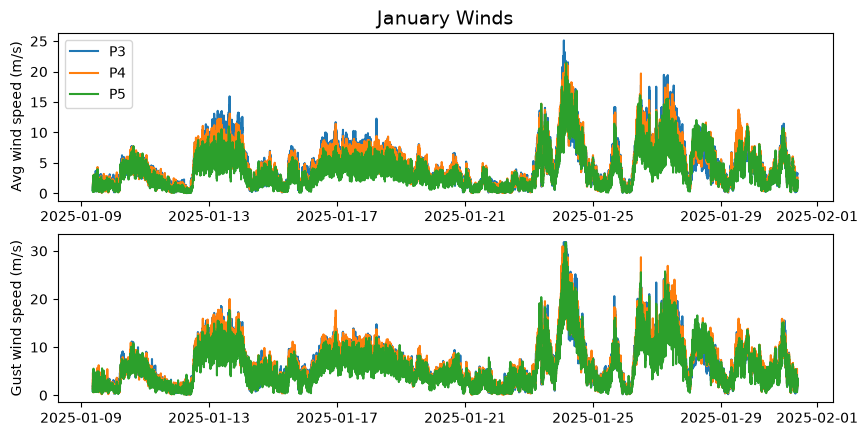

In [37]:
fig, ax = plt.subplots(2,1, figsize=(10, 4.8))

ax[0].plot(wind_df.index, wind_df['p3_avg_wdsp'], label='P3')
ax[0].plot(wind_df.index, wind_df['p4_avg_wdsp'], label='P4')
ax[0].plot(wind_df.index, wind_df['p5_avg_wdsp'], label='P5')

ax[1].plot(wind_df.index, wind_df['p3_gust_wdsp'])
ax[1].plot(wind_df.index, wind_df['p4_gust_wdsp'])
ax[1].plot(wind_df.index, wind_df['p5_gust_wdsp'])

ax[0].set_ylabel('Avg wind speed (m/s)')
ax[1].set_ylabel('Gust wind speed (m/s)')
ax[0].legend(loc='upper left')
ax[0].set_title('January Winds', fontsize=14)

Text(0.5, 1.0, 'Eowyn Winds')

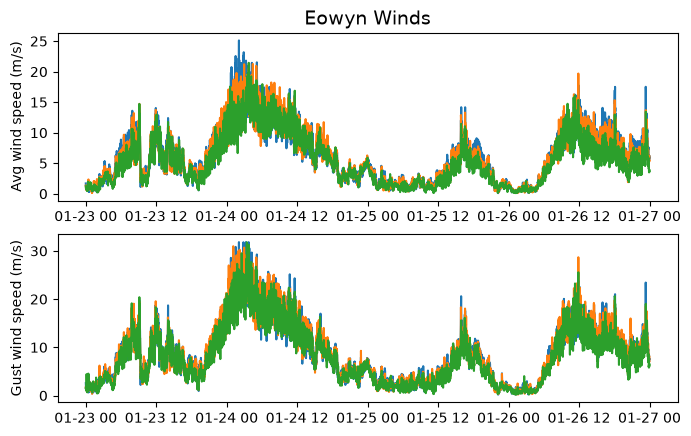

In [38]:
fig, ax = plt.subplots(2,1, figsize=(8, 4.8))

ax[0].plot(wind_df[eowyn_mask_wind].index, wind_df[eowyn_mask_wind]['p3_avg_wdsp'])
ax[0].plot(wind_df[eowyn_mask_wind].index, wind_df[eowyn_mask_wind]['p4_avg_wdsp'])
ax[0].plot(wind_df[eowyn_mask_wind].index, wind_df[eowyn_mask_wind]['p5_avg_wdsp'])

ax[1].plot(wind_df[eowyn_mask_wind].index, wind_df[eowyn_mask_wind]['p3_gust_wdsp'])
ax[1].plot(wind_df[eowyn_mask_wind].index, wind_df[eowyn_mask_wind]['p4_gust_wdsp'])
ax[1].plot(wind_df[eowyn_mask_wind].index, wind_df[eowyn_mask_wind]['p5_gust_wdsp'])

ax[0].set_ylabel('Avg wind speed (m/s)')
ax[1].set_ylabel('Gust wind speed (m/s)')

ax[0].set_title('Eowyn Winds', fontsize=14)

Text(0.5, 1.0, 'Wind rose for whole month')

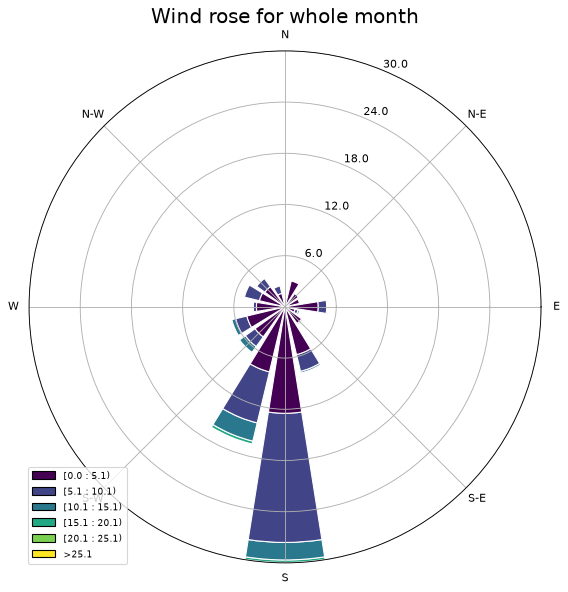

In [45]:
## Windroses
sensor = 'p3'
ax = WindroseAxes.from_ax()
ax.bar(wind_df[f'{sensor}_dir'], wind_df[f'{sensor}_avg_wdsp'], normed=True, opening=0.8, edgecolor="white")
ax.set_legend()
ax.set_title('Wind rose for whole month', fontsize=18)

Text(0.5, 1.0, 'Wind rose for Eowyn, p5')

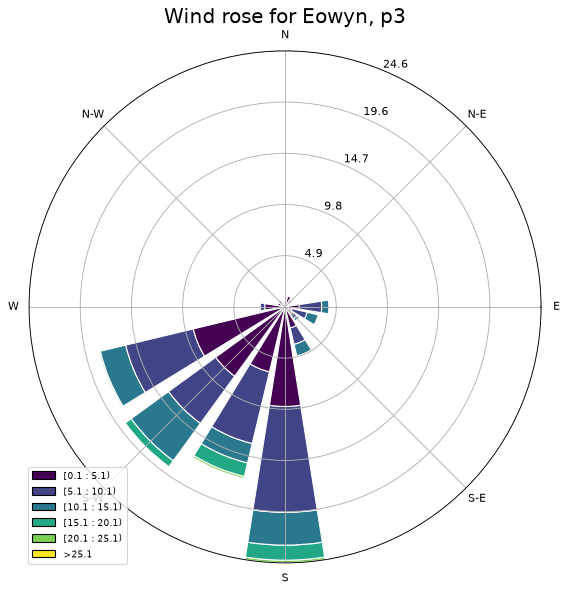

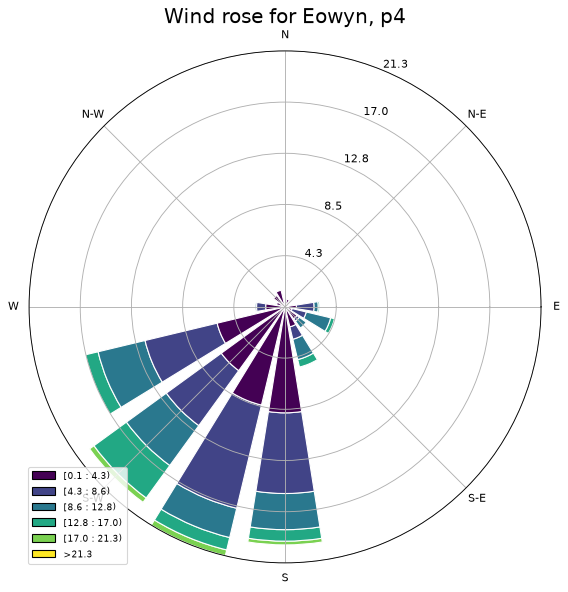

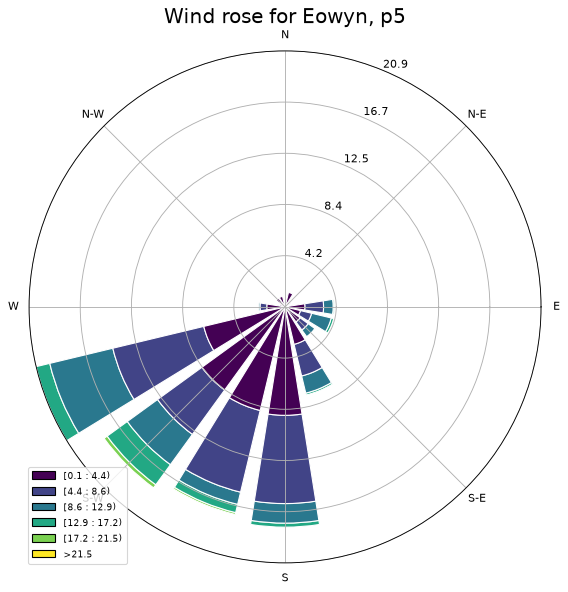

In [54]:
sensor = 'p3'
ax = WindroseAxes.from_ax()
ax.bar(wind_df[eowyn_mask_wind][f'{sensor}_dir'], wind_df[eowyn_mask_wind][f'{sensor}_avg_wdsp'], normed=True, opening=0.8, edgecolor="white")
ax.set_legend()
ax.set_title(f'Wind rose for Eowyn, {sensor}', fontsize=18)

sensor = 'p4'
ax = WindroseAxes.from_ax()
ax.bar(wind_df[eowyn_mask_wind][f'{sensor}_dir'], wind_df[eowyn_mask_wind][f'{sensor}_avg_wdsp'], normed=True, opening=0.8, edgecolor="white")
ax.set_legend()
ax.set_title(f'Wind rose for Eowyn, {sensor}', fontsize=18)

sensor = 'p5'
ax = WindroseAxes.from_ax()
ax.bar(wind_df[eowyn_mask_wind][f'{sensor}_dir'], wind_df[eowyn_mask_wind][f'{sensor}_avg_wdsp'], normed=True, opening=0.8, edgecolor="white")
ax.set_legend()
ax.set_title(f'Wind rose for Eowyn, {sensor}', fontsize=18)

# Very different win characterstics at each sensor

### Calculate the displacement of the bridge at each strain gauge
Account for temperature and other effects by subracting 60 min rolling average from the strain readings before calculation

In [87]:
def displacement(BR, TR, TL, BL):
    return np.abs( ((BR+TR)/2) - ((BL+TL)/2) )


displacement_df = pd.DataFrame(columns=['dis1', 'dis2', 'dis3', 'dis4', 'dis5', 'dis6'])

rolling_avg_strain_df = strain_df.rolling(60, min_periods=1).mean()

for i in range(1,7):
    displacement_df[f'dis{i}'] = displacement(strain_df[f'BR{i}']-rolling_avg_strain_df[f'BR{i}'], strain_df[f'TR{i}']-rolling_avg_strain_df[f'TR{i}'], strain_df[f'TL{i}']-rolling_avg_strain_df[f'TL{i}'], strain_df[f'BL{i}']-rolling_avg_strain_df[f'BL{i}'])

displacement_df.head()
#rolling_avg_strain_df.head()

,dis1,dis2,dis3,dis4,dis5,dis6
timeIndex,,,,,,
2025-01-01 08:50:00,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
2025-01-01 08:51:00,4.120500,0.230250,0.002750,0.001000,0.02625,0.046250
2025-01-01 08:52:00,1.615667,1.604500,0.025500,0.000667,0.01750,0.030833
2025-01-01 08:53:00,1.530875,1.750875,0.004125,0.107375,0.26625,0.039500
2025-01-01 08:54:00,1.049100,0.463500,0.061500,0.030700,0.26020,0.044800


(0.0, 0.7)

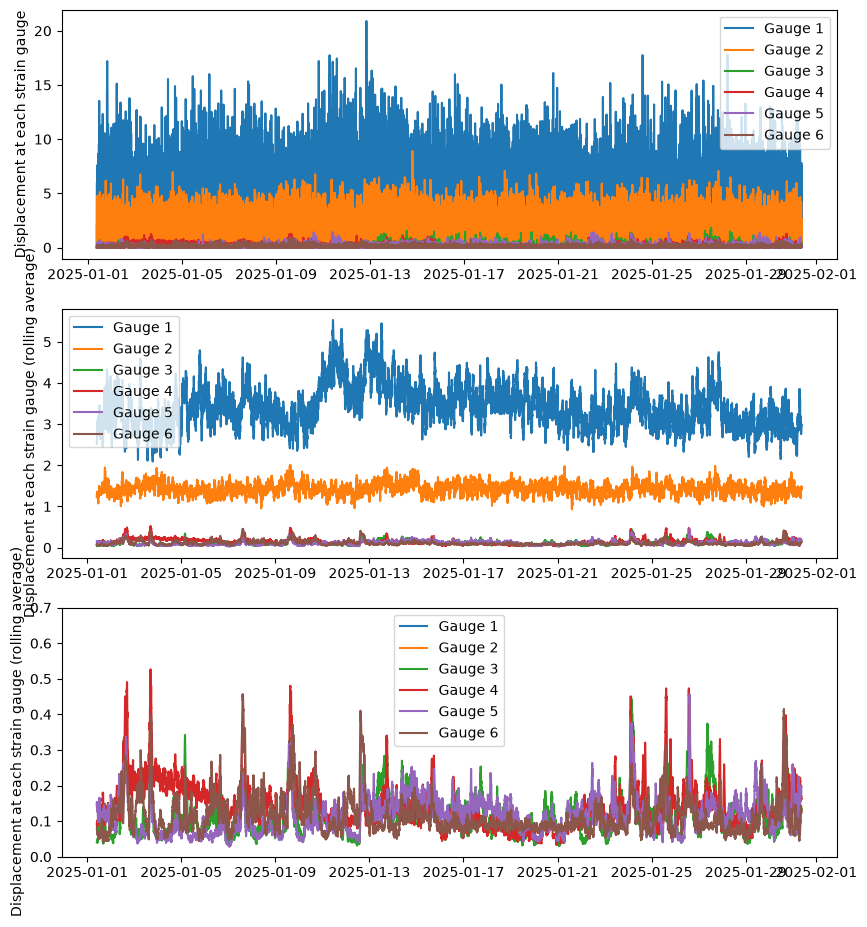

In [90]:
fig, ax = plt.subplots(3,1, figsize=(10, 11))

for gauge in displacement_df.columns:
    ax[0].plot(displacement_df.index, displacement_df[gauge])

ax[0].legend([f'Gauge {i}' for i in range(1, len(displacement_df.columns)+1)])
ax[0].set_ylabel('Displacement at each strain gauge')

# Plot rolling average of the displacement for visual clarity
for gauge in displacement_df.columns:
    ax[1].plot(displacement_df.index, displacement_df[gauge].rolling(60).mean())

ax[1].legend([f'Gauge {i}' for i in range(1, len(displacement_df.columns)+1)])
ax[1].set_ylabel('Displacement at each strain gauge (rolling average)')

# Zoom in on just 3-6
for gauge in displacement_df.columns:
    ax[2].plot(displacement_df.index, displacement_df[gauge].rolling(60).mean())

ax[2].legend([f'Gauge {i}' for i in range(1, len(displacement_df.columns)+1)])
ax[2].set_ylabel('Displacement at each strain gauge (rolling average)')
ax[2].set_ylim(0,0.7)


Sensors 1 and 2 are notably different from the others, possibly due to distance from shore or from a pylon, but further investigation is required to determine the cause for certain. It may be in part due to very different wind characteristics at different locations along the bridge (as found in the wind roses for each wind sensor), although again, this is requires further study to confirm or reject and is unlikely to be the sole cause.

### Calculate displacement at each pylon/wind sensor
This is done simply as the mean of the two nearest strain gauges to each sensor (one on either side). More sophisticated methods (interpolation by distance, weighed averages, fitting a curve to the strain gauges and sampling at pylon locations, etc) are discussed in the report, but this is sufficient for a preliminary investigation.

In [92]:
displacement_df['p3'] = (displacement_df['dis1'] + displacement_df['dis2'])/2
displacement_df['p4'] = (displacement_df['dis3'] + displacement_df['dis4'])/2
displacement_df['p5'] = (displacement_df['dis5'] + displacement_df['dis6'])/2

(0.0, 0.7)

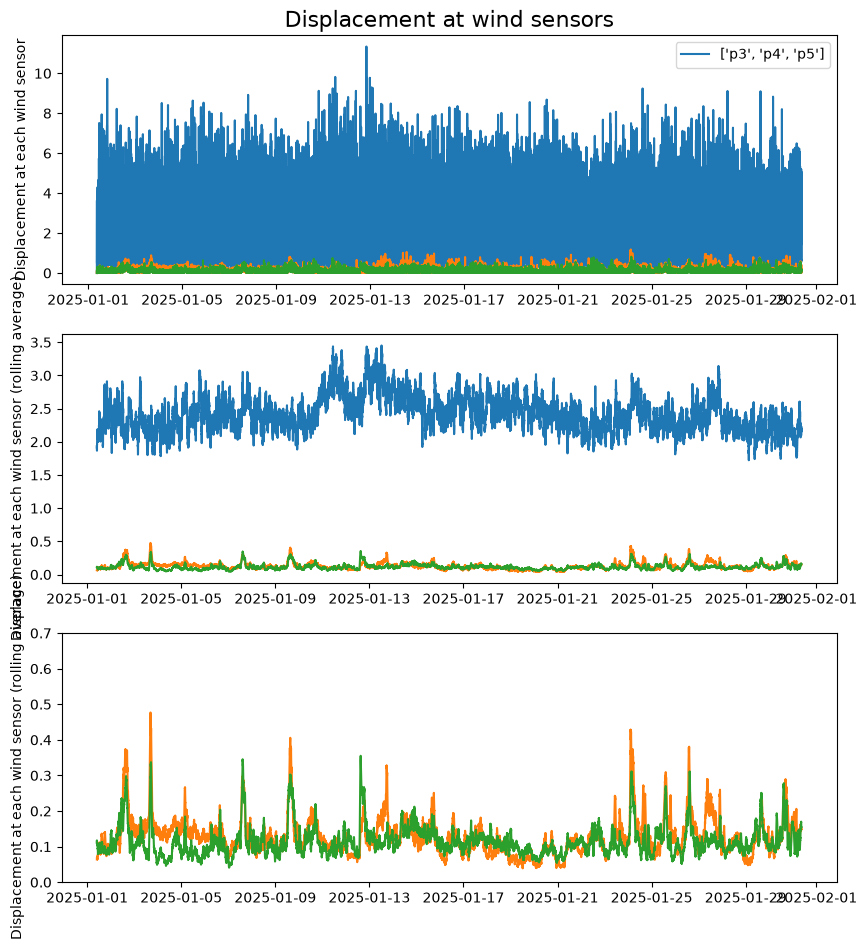

In [94]:
fig, ax = plt.subplots(3,1, figsize=(10, 11))

ax[0].set_title('Displacement at wind sensors', fontsize=16)

for gauge in ['p3', 'p4', 'p5']:
    ax[0].plot(displacement_df.index, displacement_df[gauge])

ax[0].legend([['p3', 'p4', 'p5']])
ax[0].set_ylabel('Displacement at each wind sensor')

# Plot rolling average of the displacement for visual clarity
for gauge in ['p3', 'p4' ,'p5']:
    ax[1].plot(displacement_df.index, displacement_df[gauge].rolling(60).mean())

ax[1].set_ylabel('Displacement at each wind sensor (rolling average)')

# Zoom in on just 3-6
for gauge in ['p3', 'p4' ,'p5']:
    ax[2].plot(displacement_df.index, displacement_df[gauge].rolling(60).mean())

ax[2].set_ylabel('Displacement at each wind sensor (rolling average)')
ax[2].set_ylim(0,0.7)

The sensor at pylon 3 is so different from the others due to the odd readings at gauges 1 and 2. A more sophisticated interpolation method may help, as well as getting more data to determine whether the higher strain at 1 and 2 is physical or an error, and what the cause might be.

The final step is to merge the wind readings and displacement readings via the same merge_asof method as above to determine the structural response to each wind observation. This will focus on just Storm Eowyn for clarity, a more rigorous treatment would study the whole month and compare the response under calm conditions to stormy.

In [103]:
wind_df['time_index'] = wind_df.index
displacement_df['time_index'] = displacement_df.index

wind_dis_df = pd.merge_asof(
        wind_df, displacement_df,
        on='time_index',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )

wind_dis_df = wind_dis_df.set_index('time_index')
wind_dis_df = wind_dis_df.dropna()

eowyn_mask_both = (wind_dis_df.index > eowyn_start) & (wind_dis_df.index <= eowyn_end)

wind_dis_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 31658 entries, 2025-01-09 08:51:20 to 2025-01-31 08:47:31
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   p3_avg_wdsp   31658 non-null  float64       
 1   p3_gust_wdsp  31658 non-null  float64       
 2   p3_dir        31658 non-null  float64       
 3   p4_avg_wdsp   31658 non-null  float64       
 4   p4_gust_wdsp  31658 non-null  float64       
 5   p4_dir        31658 non-null  float64       
 6   p5_avg_wdsp   31658 non-null  float64       
 7   p5_gust_wdsp  31658 non-null  float64       
 8   p5_dir        31658 non-null  float64       
 9   timeIndex     31658 non-null  datetime64[us]
 10  dis1          31658 non-null  float64       
 11  dis2          31658 non-null  float64       
 12  dis3          31658 non-null  float64       
 13  dis4          31658 non-null  float64       
 14  dis5          31658 non-null  float64       
 15  dis6        

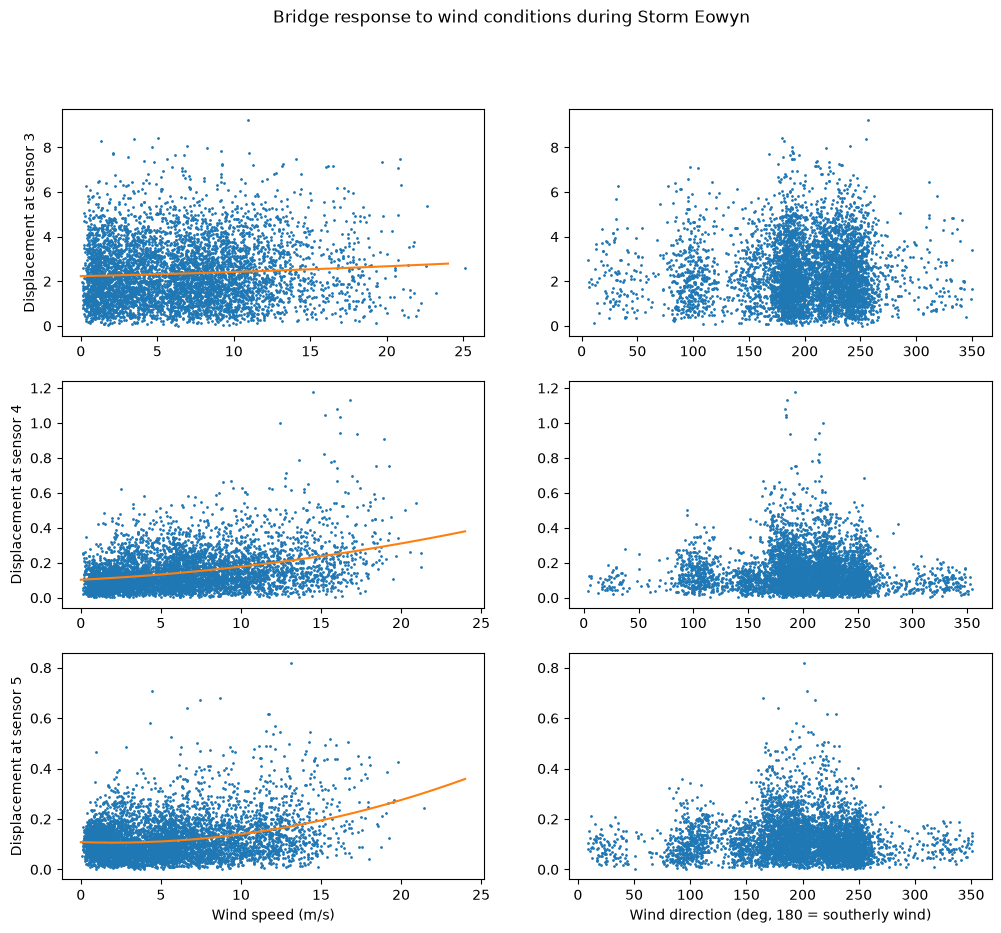

In [129]:
fig, ax = plt.subplots(3,2, figsize = (12,10))

coefficients = np.polyfit(wind_dis_df[eowyn_mask_both]['p3_avg_wdsp'], wind_dis_df[eowyn_mask_both]['p3'], 2)

ax[0,0].scatter(wind_dis_df[eowyn_mask_both]['p3_avg_wdsp'], wind_dis_df[eowyn_mask_both]['p3'], s=1)
ax[0,0].plot(np.arange(0,25,1), coefficients[0]*np.arange(0,25,1)**2 + coefficients[1]*np.arange(0,25,1) + coefficients[2], color='tab:orange')


coefficients = np.polyfit(wind_dis_df[eowyn_mask_both]['p4_avg_wdsp'], wind_dis_df[eowyn_mask_both]['p4'], 2)

ax[1,0].scatter(wind_dis_df[eowyn_mask_both]['p4_avg_wdsp'], wind_dis_df[eowyn_mask_both]['p4'], s=1)
ax[1,0].plot(np.arange(0,25,1), coefficients[0]*np.arange(0,25,1)**2 + coefficients[1]*np.arange(0,25,1) + coefficients[2], color='tab:orange')


coefficients = np.polyfit(wind_dis_df[eowyn_mask_both]['p5_avg_wdsp'], wind_dis_df[eowyn_mask_both]['p5'], 2)

ax[2,0].scatter(wind_dis_df[eowyn_mask_both]['p5_avg_wdsp'], wind_dis_df[eowyn_mask_both]['p5'], s=1)
ax[2,0].plot(np.arange(0,25,1), coefficients[0]*np.arange(0,25,1)**2 + coefficients[1]*np.arange(0,25,1) + coefficients[2], color='tab:orange')


## Plot response vs wind direction
coefficients = np.polyfit(wind_dis_df[eowyn_mask_both]['p3_dir'], wind_dis_df[eowyn_mask_both]['p3'], 2)

ax[0,1].scatter(wind_dis_df[eowyn_mask_both]['p3_dir'], wind_dis_df[eowyn_mask_both]['p3'], s=1)
#ax[0,1].plot(np.arange(0,360,1), coefficients[0]*np.arange(0,360,1)**2 + coefficients[1]*np.arange(0,360,1) + coefficients[2], color='tab:orange')


coefficients = np.polyfit(wind_dis_df[eowyn_mask_both]['p4_dir'], wind_dis_df[eowyn_mask_both]['p4'], 2)

ax[1,1].scatter(wind_dis_df[eowyn_mask_both]['p4_dir'], wind_dis_df[eowyn_mask_both]['p4'], s=1)
#ax[1,1].plot(np.arange(0,360,1), coefficients[0]*np.arange(0,360,1)**2 + coefficients[1]*np.arange(0,360,1) + coefficients[2], color='tab:orange')


coefficients = np.polyfit(wind_dis_df[eowyn_mask_both]['p5_dir'], wind_dis_df[eowyn_mask_both]['p5'], 2)

ax[2,1].scatter(wind_dis_df[eowyn_mask_both]['p5_dir'], wind_dis_df[eowyn_mask_both]['p5'], s=1)
#ax[2,1].plot(np.arange(0,360,1), coefficients[0]*np.arange(0,360,1)**2 + coefficients[1]*np.arange(0,360,1) + coefficients[2], color='tab:orange')

fig.suptitle('Bridge response to wind conditions during Storm Eowyn')
ax[2,0].set_xlabel('Wind speed (m/s)')
ax[2,1].set_xlabel('Wind direction (deg, 180 = southerly wind)')
for i in range(3,6):
    ax[i-3,0].set_ylabel(f'Displacement at sensor {i}')

Due to time constraints, I cannot take this analysis any further, however these plots already provide valuable insights into teh bridge response to wind speed vs direction. The wind direction plots show a peak at ~190deg. Knowing that the peak windspeeds did not occur when the wind was directly southerly, this indicates that the wind direction normal to the bridge orientation (approx. east-west) generated a greater response than the peak winds occuring at oblique angles (south-westerly, later in the progression of Storm Eowyn).

Further investigation is required to confirm this and to more fully decompose the relative contributions of speed vs direction. Within Storm Eowyn, the displacement observations at each stage of the storm (southerly wind progressing to westerly) should be plotted separately. Similarly, the rest of the month should be investigated and plotted by momentary wind direction. As demonstrated by the wind roses plotted during EDA, the wind patterns at the bridge are very consistently southerly, so gathering sufficient data for other wind directions may be difficult.

Finally, it is worth noting that the approximately quadratic relation between windspeed and bridge response reported in the provided literature was reproduced for sensors 4 and 5. The cause of the different behaviour of the sensor at P3 is unknown and possible causes have been discussed above.
